# V13 — Análise bivariada

Esta versão parte do V11 e acrescenta a **análise bivariada** (features × target) depois do mapa de calor de correlação. O modelo e as métricas não mudam: a análise serve para entender e justificar as features.

**Objetivo:** prever quais clientes vão cancelar o serviço (churn) com regressão logística.

## Extração dos dados

### Bibliotecas

In [1]:
import json
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

## Funcoes do pipeline

Cada função recebe tudo o que usa por parâmetro e não depende de variáveis definidas em outras células.

In [2]:
def carregar_base(caminho):
    return pd.read_csv(caminho)

def renomear_colunas(df, mapa):
    return df.rename(columns=mapa)

def converter_target_binario(df, mapa, coluna="target"):
    df = df.copy()
    df[coluna] = df[coluna].map(mapa)
    return df

def remover_colunas(df, colunas):
    return df.drop(columns=list(colunas))

def codificar_categoricas(df, colunas_sim_nao, mapa_sim_nao, colunas_addons, mapa_addon,
                          mapa_multiplas_linhas, mapa_tipo_contrato, colunas_one_hot):
    """Converte todas as colunas categóricas em números, conforme os mapas recebidos."""
    df = df.copy()

    for coluna in colunas_sim_nao:
        df[coluna] = df[coluna].map(mapa_sim_nao)
    for coluna in colunas_addons:
        df[coluna] = df[coluna].map(mapa_addon)
    df["possui_multiplas_linhas"] = df["possui_multiplas_linhas"].map(mapa_multiplas_linhas)
    df["tipo_contrato"] = df["tipo_contrato"].map(mapa_tipo_contrato)

    for coluna, mapa in colunas_one_hot.items():
        dummies = pd.get_dummies(df[coluna].map(mapa), prefix=coluna, dtype=int)
        df = pd.concat([df.drop(columns=coluna), dummies], axis=1)

    return df

def exibir_estrutura(df):
    df.info()

def identificar_clientes_sem_fatura(df, coluna_total_cobrado):
    total_cobrado_numerico = pd.to_numeric(df[coluna_total_cobrado], errors="coerce")
    return (df["meses_como_cliente"] == 0) & total_cobrado_numerico.isna()

def diagnosticar_ausentes(df, coluna_total_cobrado):
    print(f"Nulos encontrados pelo isna(): {df.isna().sum().sum()}")

    total_cobrado_numerico = pd.to_numeric(df[coluna_total_cobrado], errors="coerce")
    clientes_sem_fatura = identificar_clientes_sem_fatura(df, coluna_total_cobrado)
    print(f"Valores em branco no total cobrado: {total_cobrado_numerico.isna().sum()}")

    return df[clientes_sem_fatura]

def remover_clientes_sem_fatura(df, coluna_total_cobrado):
    total_cobrado_numerico = pd.to_numeric(df[coluna_total_cobrado], errors="coerce")
    clientes_sem_fatura = identificar_clientes_sem_fatura(df, coluna_total_cobrado)

    df_limpo = df[~clientes_sem_fatura].copy()
    df_limpo[coluna_total_cobrado] = total_cobrado_numerico[~clientes_sem_fatura]

    print(f"Registros iniciais: {len(df)}, Registros atuais: {len(df_limpo)}, Registros removidos: {clientes_sem_fatura.sum()}")
    return df_limpo

def adicionar_quantidade_de_addons(df, colunas_addons):
    df = df.copy()
    df["quantidade_de_addons"] = df[colunas_addons].sum(axis=1)
    return df

def exibir_distribuicao_e_correlacao(df, colunas_distribuicao, limiar_correlacao=0.5):
    fig, axes = plt.subplots(1, len(colunas_distribuicao), figsize=(20, 4))
    for ax, coluna in zip(axes, colunas_distribuicao):
        sns.histplot(df[coluna], kde=True, ax=ax, color="coral")
        ax.set_title(f"Distribuicao: {coluna}", fontweight="bold")
    plt.tight_layout()
    plt.show()

    matriz_correlacao = df.drop(columns="target").corr()

    plt.figure(figsize=(16, 12))
    sns.heatmap(matriz_correlacao, cmap="coolwarm", center=0, square=True, linewidths=0.3)
    plt.title("Mapa de calor de correlacao entre variaveis preditoras", fontweight="bold")
    plt.tight_layout()
    plt.show()

    # Mantém só o triângulo superior da matriz para não repetir os pares
    pares = matriz_correlacao.where(np.triu(np.ones(matriz_correlacao.shape, dtype=bool), k=1)).stack()
    pares_alta_correlacao = pares[pares.abs() >= limiar_correlacao].sort_values(key=abs, ascending=False)
    print(f"Pares de features preditoras com |correlacao| >= {limiar_correlacao}:")
    print(pares_alta_correlacao.round(3).to_string())

    print("\nCorrelacao de cada feature com o target:")
    print(df.corr()["target"].drop("target").sort_values(key=abs, ascending=False).round(3).to_string())

def categoria_original(df, prefixo):
    """Reconstrói a categoria original a partir das colunas one-hot (ex.: possui_servico_de_internet_dsl → dsl)."""
    colunas = [coluna for coluna in df.columns if coluna.startswith(f"{prefixo}_")]
    return df[colunas].idxmax(axis=1).str.removeprefix(f"{prefixo}_")

def exibir_taxa_churn_por_categoria(df, variaveis_categoricas):
    taxa_media_de_churn = df["target"].mean()

    fig, axes = plt.subplots(2, 4, figsize=(22, 10))
    amplitude_por_variavel = {}
    for ax, (nome, categoria) in zip(axes.ravel(), variaveis_categoricas.items()):
        taxa_por_categoria = df["target"].groupby(categoria, observed=False).mean()
        amplitude_por_variavel[nome] = taxa_por_categoria.max() - taxa_por_categoria.min()

        taxa_por_categoria.plot.bar(ax=ax, color="coral")
        ax.bar_label(ax.containers[0], labels=[f"{taxa:.0%}" for taxa in taxa_por_categoria])
        ax.axhline(taxa_media_de_churn, linestyle="--", color="gray", label=f"media ({taxa_media_de_churn:.0%})")
        ax.set_title(f"Taxa de churn por {nome}", fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Taxa de churn")
        ax.tick_params(axis="x", rotation=30)
        ax.legend()
    plt.tight_layout()
    plt.show()

    # Quanto maior a diferença entre a maior e a menor taxa, mais a variável separa quem cancela de quem fica
    print("Diferenca entre a maior e a menor taxa de churn de cada variavel:")
    print(pd.Series(amplitude_por_variavel).sort_values(ascending=False).map("{:.0%}".format).to_string())

def exibir_distribuicao_por_target(df, colunas):
    fig, axes = plt.subplots(1, len(colunas), figsize=(20, 5))
    for ax, coluna in zip(axes, colunas):
        sns.boxplot(data=df, x="target", y=coluna, hue="target", palette=["lightblue", "coral"], legend=False, ax=ax)
        ax.set_xticks([0, 1], ["Nao cancelou", "Cancelou"])
        ax.set_xlabel("")
        ax.set_title(f"{coluna} por target", fontweight="bold")
    plt.tight_layout()
    plt.show()

    print("Mediana de cada variavel por target:")
    return df.groupby("target")[colunas].median().rename(index={0: "Nao cancelou", 1: "Cancelou"}).round(2)

def remover_duplicatas(df):
    df_sem_duplicatas = df.drop_duplicates()
    print(f"Linhas duplicadas encontradas: {len(df) - len(df_sem_duplicatas)}")
    print(f"Registros antes: {len(df)}, Registros depois: {len(df_sem_duplicatas)}")
    return df_sem_duplicatas

def exibir_proporcao_target(df, rotulos):
    contagem_target = df["target"].value_counts().sort_index()

    print("Contagem:")
    print(contagem_target.to_string())
    print("\nPercentual:")
    for rotulo, percentual in zip(rotulos, contagem_target / contagem_target.sum() * 100):
        print(f"{rotulo}: {percentual:.2f}%")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].bar(rotulos, contagem_target.values, color=["lightblue", "coral"])
    axes[0].set_ylabel("Frequencia")
    axes[0].set_title("Distribuicao da Variavel Target")
    axes[0].grid(axis="y", alpha=0.3)
    axes[1].pie(contagem_target.values, labels=rotulos, autopct="%1.1f%%", colors=["lightblue", "coral"], startangle=90)
    axes[1].set_title("Proporcao de Classes")
    plt.tight_layout()
    plt.show()

    print(f"\nRatio de balanceamento: {contagem_target.min() / contagem_target.max():.2f}")

def exibir_dispersao(df, colunas):
    fig, axes = plt.subplots(1, len(colunas), figsize=(20, 4))
    for ax, coluna in zip(axes, colunas):
        sns.boxplot(x=df[coluna], ax=ax, color="coral")
        quantidade_outliers = (np.abs(stats.zscore(df[coluna])) > 3).sum()
        ax.set_title(f"Boxplot: {coluna}\nOutliers: {quantidade_outliers}", fontweight="bold")
        ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

def descrever_colunas(df, colunas):
    return df[list(colunas)].describe().round(2)

def dividir_treino_teste(df, proporcao_teste, random_state):
    X = df.drop(columns="target")
    y = df["target"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=proporcao_teste, random_state=random_state, stratify=y
    )

    print(f"X_train: {X_train.shape}, X_test: {X_test.shape}, y_train: {y_train.shape}, y_test: {y_test.shape}")
    return X, y, X_train, X_test, y_train, y_test

def resumir_churn_por_faixa(X_treino, y_treino, faixas_de_meses):
    faixas_treino = pd.cut(X_treino["meses_como_cliente"], faixas_de_meses, include_lowest=True)
    return y_treino.groupby(faixas_treino, observed=False).agg(clientes="size", taxa_de_churn="mean").round(3)

def adicionar_taxa_de_churn_por_faixa_de_meses(X_treino, X_avaliacao, y_treino, faixas_de_meses):
    """Troca meses_como_cliente pela taxa de churn da faixa, aprendida apenas com o treino."""
    X_treino, X_avaliacao = X_treino.copy(), X_avaliacao.copy()
    faixa_treino = pd.cut(X_treino["meses_como_cliente"], faixas_de_meses, include_lowest=True)
    faixa_avaliacao = pd.cut(X_avaliacao["meses_como_cliente"], faixas_de_meses, include_lowest=True)

    # Média do target (0/1) em cada faixa = % de clientes que cancelaram naquela faixa
    taxa_de_churn_por_faixa = y_treino.groupby(faixa_treino, observed=False).mean()

    X_treino["taxa_churn_faixa_meses"] = faixa_treino.map(taxa_de_churn_por_faixa).astype(float)
    X_avaliacao["taxa_churn_faixa_meses"] = faixa_avaliacao.map(taxa_de_churn_por_faixa).astype(float)

    return X_treino.drop(columns="meses_como_cliente"), X_avaliacao.drop(columns="meses_como_cliente")

def preparar_para_treino(X_treino, X_avaliacao, y_treino, faixas_de_meses, colunas_para_escalonar, random_state):
    """Aplica taxa por faixa, escalonamento e SMOTE. Retorna treino balanceado e avaliação transformada."""
    X_treino, X_avaliacao = adicionar_taxa_de_churn_por_faixa_de_meses(X_treino, X_avaliacao, y_treino, faixas_de_meses)

    escalonador = StandardScaler()
    X_treino[colunas_para_escalonar] = escalonador.fit_transform(X_treino[colunas_para_escalonar])
    X_avaliacao[colunas_para_escalonar] = escalonador.transform(X_avaliacao[colunas_para_escalonar])

    X_treino_balanceado, y_treino_balanceado = SMOTE(random_state=random_state).fit_resample(X_treino, y_treino)
    return X_treino_balanceado, y_treino_balanceado, X_avaliacao

def treinar_modelo(X_treino, y_treino, parametros_modelo):
    """Treina a regressão logística com penalidade L1 (Lasso)."""
    return LogisticRegression(**parametros_modelo).fit(X_treino, y_treino)

def avaliar_modelo(modelo, X_avaliacao, y_avaliacao):
    """Calcula as métricas de classificação do modelo (limiar padrão de 0,5)."""
    y_previsto = modelo.predict(X_avaliacao)
    y_proba = modelo.predict_proba(X_avaliacao)[:, 1]
    return {
        "acuracia": accuracy_score(y_avaliacao, y_previsto),
        "precisao": precision_score(y_avaliacao, y_previsto),
        "recall": recall_score(y_avaliacao, y_previsto),
        "f1_score": f1_score(y_avaliacao, y_previsto),
        "roc_auc": roc_auc_score(y_avaliacao, y_proba),
    }

def validar_em_kfold(X, y, faixas_de_meses, colunas_para_escalonar, parametros_modelo, n_folds, random_state):
    k_fold_estratificado = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=random_state)

    metricas_por_fold = []
    for numero_fold, (indice_treino, indice_validacao) in enumerate(k_fold_estratificado.split(X, y), start=1):
        X_treino_fold, y_treino_fold, X_validacao_fold = preparar_para_treino(
            X.iloc[indice_treino], X.iloc[indice_validacao], y.iloc[indice_treino],
            faixas_de_meses, colunas_para_escalonar, random_state
        )
        modelo_fold = treinar_modelo(X_treino_fold, y_treino_fold, parametros_modelo)
        metricas_por_fold.append({"fold": numero_fold, **avaliar_modelo(modelo_fold, X_validacao_fold, y.iloc[indice_validacao])})

    return pd.DataFrame(metricas_por_fold)

def exibir_metricas_kfold(tabela_metricas_cv):
    print("Metricas por fold:")
    print(tabela_metricas_cv.round(4).to_string(index=False))

    print(f"\nMedia +/- desvio padrao entre os {len(tabela_metricas_cv)} folds:")
    for coluna in tabela_metricas_cv.columns.drop("fold"):
        print(f"{coluna}: {tabela_metricas_cv[coluna].mean():.4f} +/- {tabela_metricas_cv[coluna].std():.4f}")

def exibir_coeficientes_lasso(modelo, colunas):
    coeficientes_lasso = pd.Series(modelo.coef_[0], index=colunas)
    features_zeradas_pelo_lasso = coeficientes_lasso[coeficientes_lasso == 0].index.tolist()
    print(f"Features zeradas pelo Lasso ({len(features_zeradas_pelo_lasso)}): {features_zeradas_pelo_lasso}")
    print("\nCoeficientes ordenados por magnitude:")
    print(coeficientes_lasso.sort_values(key=abs, ascending=False).to_string())
    return features_zeradas_pelo_lasso

def calcular_matriz_e_roc(modelo, X_avaliacao, y_avaliacao):
    y_pred = modelo.predict(X_avaliacao)
    y_proba = modelo.predict_proba(X_avaliacao)[:, 1]
    matriz_confusao = confusion_matrix(y_avaliacao, y_pred)
    fpr, tpr, _ = roc_curve(y_avaliacao, y_proba)
    return matriz_confusao, fpr, tpr

def exibir_metricas_classificacao(metricas, matriz_confusao):
    print()
    for nome, valor in metricas.items():
        print(f"{nome}: {valor:.4f}")
    print("Matriz de confusao:")
    print(matriz_confusao)

def exibir_matriz_e_roc(matriz_confusao, fpr, tpr, roc_auc):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=["Nao cancelou", "Cancelou"]).plot(ax=axes[0], cmap="Blues")
    axes[0].set_title("Matriz de Confusao")
    axes[1].plot(fpr, tpr, color="coral", label=f"ROC AUC = {roc_auc:.4f}")
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[1].set_xlabel("Taxa de Falsos Positivos")
    axes[1].set_ylabel("Taxa de Verdadeiros Positivos")
    axes[1].set_title("Curva ROC")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

def salvar_metricas(metricas, diretorio):
    diretorio = Path(diretorio)
    diretorio.mkdir(parents=True, exist_ok=True)
    with open(diretorio / "metrics.json", "w") as arquivo_metricas:
        json.dump(metricas, arquivo_metricas, indent=4)

def consultar_metricas_dvc(diretorio_projeto):
    resultado_dvc = subprocess.run(["dvc", "metrics", "show"], cwd=diretorio_projeto, capture_output=True, text=True)
    print(resultado_dvc.stdout)
    print(resultado_dvc.stderr)
    return resultado_dvc


### Carregamento

In [3]:
caminho_dataset = Path("../../../data/raw/Telco-Customer-Churn.csv")

df_bruto = carregar_base(caminho_dataset)

df_bruto.head(n=100)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Tradução das colunas para português

In [4]:
colunas_pt_br = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "cliente_em_idade_avancada",
    "Partner": "casado",
    "Dependents": "dependentes",
    "tenure": "meses_como_cliente",
    "PhoneService": "possui_servico_telefonico",
    "MultipleLines": "possui_multiplas_linhas",
    "InternetService": "possui_servico_de_internet",
    "OnlineSecurity": "possui_seguranca_online",
    "OnlineBackup": "possui_backup_online",
    "DeviceProtection": "possui_protecao_dispositivo",
    "TechSupport": "possui_suporte_tecnico_premium",
    "StreamingTV": "possui_streaming_tv_terceiros",
    "StreamingMovies": "possui_streaming_filmes_terceiros",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "fatura_sem_papel",
    "PaymentMethod": "metodo_pagamento",
    "MonthlyCharges": "cobranca_mensal",
    "TotalCharges": "total_cobrado_acumulado",
    "Churn": "target",
}

df_traduzido = renomear_colunas(df_bruto, colunas_pt_br)

df_traduzido.head(n=100)

,id_cliente,genero,cliente_em_idade_avancada,casado,dependentes,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_acumulado,target
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Target binário

`Churn` vira `target`: **1 = cancelou**, **0 = não cancelou**.

In [5]:
df_traduzido = converter_target_binario(df_traduzido, {"Yes": 1, "No": 0})

df_traduzido["target"].value_counts()

target
0    5174
1    1869
Name: count, dtype: int64

## Remoção de features sensíveis

- `id_cliente`: identificador único, não tem relação com o comportamento do cliente.
- `genero` e `dependentes`: atributos sensíveis, removidos para evitar decisões discriminatórias.

In [6]:
colunas_sensiveis = ["id_cliente", "genero", "dependentes"]

df_sem_sensiveis = remover_colunas(df_traduzido, colunas_sensiveis)

df_sem_sensiveis.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_acumulado,target
0,0,Yes,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,0,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,0,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,0,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,0,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,1
96,0,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,0
97,0,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,1
98,0,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,0


## Codificação das features categóricas

O modelo só trabalha com números, então cada tipo de coluna categórica recebe um tratamento:

| Tipo | Colunas | Codificação |
|---|---|---|
| Sim/Não | `casado`, `fatura_sem_papel`, `possui_servico_telefonico` | `Yes` → 1, `No` → 0 |
| Addons de internet | segurança, backup, proteção, suporte, streaming de TV e de filmes | `Yes` → 1; `No` e `No internet service` → 0 |
| Múltiplas linhas | `possui_multiplas_linhas` | `Yes` → 1; `No` e `No phone service` → 0 |
| Ordinal | `tipo_contrato` | mensal → 0, 1 ano → 1, 2 anos → 2 (existe uma ordem natural) |
| Sem ordem | `possui_servico_de_internet`, `metodo_pagamento` | One-hot: uma coluna 0/1 para cada categoria |

In [7]:
mapa_sim_nao = {"Yes": 1, "No": 0}
colunas_sim_nao = ["casado", "fatura_sem_papel", "possui_servico_telefonico"]

colunas_addons = [
    "possui_seguranca_online",
    "possui_backup_online",
    "possui_protecao_dispositivo",
    "possui_suporte_tecnico_premium",
    "possui_streaming_tv_terceiros",
    "possui_streaming_filmes_terceiros",
]
mapa_addon = {"Yes": 1, "No": 0, "No internet service": 0}
mapa_multiplas_linhas = {"Yes": 1, "No": 0, "No phone service": 0}
mapa_tipo_contrato = {"Month-to-month": 0, "One year": 1, "Two year": 2}

colunas_one_hot = {
    "possui_servico_de_internet": {"No": "sem_internet", "Fiber optic": "fibra_optica", "DSL": "dsl"},
    "metodo_pagamento": {
        "Mailed check": "mailed_check",
        "Electronic check": "electronic_check",
        "Bank transfer (automatic)": "bank_transfer_automatic",
        "Credit card (automatic)": "credit_card_automatic",
    },
}

df_codificado = codificar_categoricas(
    df_sem_sensiveis,
    colunas_sim_nao, mapa_sim_nao,
    colunas_addons, mapa_addon,
    mapa_multiplas_linhas, mapa_tipo_contrato,
    colunas_one_hot,
)

df_codificado.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_acumulado,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.5,0,1,0,0,0,0,0,1
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.7,0,1,0,0,0,1,0,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.2,0,0,0,1,1,0,0,0


## Informações estruturais

Depois da codificação, todas as colunas devem ser numéricas. A única exceção esperada é `total_cobrado_acumulado`, que vem do CSV como texto e é tratada na próxima etapa.

In [8]:
exibir_estrutura(df_codificado)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   cliente_em_idade_avancada                 7043 non-null   int64  
 1   casado                                    7043 non-null   int64  
 2   meses_como_cliente                        7043 non-null   int64  
 3   possui_servico_telefonico                 7043 non-null   int64  
 4   possui_multiplas_linhas                   7043 non-null   int64  
 5   possui_seguranca_online                   7043 non-null   int64  
 6   possui_backup_online                      7043 non-null   int64  
 7   possui_protecao_dispositivo               7043 non-null   int64  
 8   possui_suporte_tecnico_premium            7043 non-null   int64  
 9   possui_streaming_tv_terceiros             7043 non-null   int64  
 10  possui_streaming_filmes_terceiros         7043 

## Identificando missing values

O `isna()` não encontra nenhum nulo, mas isso engana: `total_cobrado_acumulado` tem **11 valores em branco (`" "`)**, que o pandas lê como texto.

Convertendo a coluna para número (`errors="coerce"` transforma o que não é número em `NaN`), esses valores aparecem. Todos pertencem a clientes com **0 meses de casa**, que ainda não receberam a primeira fatura.

In [9]:
clientes_sem_fatura_diagnosticados = diagnosticar_ausentes(df_codificado, "total_cobrado_acumulado")

clientes_sem_fatura_diagnosticados

Nulos encontrados pelo isna(): 0
Valores em branco no total cobrado: 11


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_acumulado,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
488,0,1,0,0,0,1,0,1,1,1,0,2,1,52.55,,0,1,0,0,1,0,0,0
753,0,0,0,1,0,0,0,0,0,0,0,2,0,20.25,,0,0,0,1,0,0,0,1
936,0,1,0,1,0,1,1,1,0,1,1,2,0,80.85,,0,1,0,0,0,0,0,1
1082,0,1,0,1,1,0,0,0,0,0,0,2,0,25.75,,0,0,0,1,0,0,0,1
1340,0,1,0,0,0,1,1,1,1,1,0,2,0,56.05,,0,1,0,0,0,1,0,0
3331,0,1,0,1,0,0,0,0,0,0,0,2,0,19.85,,0,0,0,1,0,0,0,1
3826,0,1,0,1,1,0,0,0,0,0,0,2,0,25.35,,0,0,0,1,0,0,0,1
4380,0,1,0,1,0,0,0,0,0,0,0,2,0,20.00,,0,0,0,1,0,0,0,1
5218,0,1,0,1,0,0,0,0,0,0,0,1,1,19.70,,0,0,0,1,0,0,0,1
6670,0,1,0,1,1,0,1,1,1,1,0,2,0,73.35,,0,1,0,0,0,0,0,1


## Removendo os missing values

Os 11 clientes sem fatura são removidos (0,16% da base). Não faz sentido imputar um valor, porque eles ainda não têm histórico de cobrança.

In [10]:
df_limpo = remover_clientes_sem_fatura(df_codificado, "total_cobrado_acumulado")

df_limpo.head(n=100)

Registros iniciais: 7043, Registros atuais: 7032, Registros removidos: 11


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_acumulado,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.50,0,1,0,0,0,0,0,1
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.70,0,1,0,0,0,1,0,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.20,0,0,0,1,1,0,0,0


## Engenharia de features: quantidade de addons contratados

Soma quantos serviços adicionais de internet o cliente tem (de 0 a 6).

In [11]:
colunas_addons = [
    "possui_seguranca_online",
    "possui_backup_online",
    "possui_protecao_dispositivo",
    "possui_suporte_tecnico_premium",
    "possui_streaming_tv_terceiros",
    "possui_streaming_filmes_terceiros",
]

df_limpo = adicionar_quantidade_de_addons(df_limpo, colunas_addons)

df_limpo.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_acumulado,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0,1
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.50,0,1,0,0,0,0,0,1,2
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1,2
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0,3
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0,1
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.70,0,1,0,0,0,1,0,0,3
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1,0
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.20,0,0,0,1,1,0,0,0,0


## Análise de distribuição e mapa de calor de correlação

Objetivos:
- ver o formato da distribuição das variáveis numéricas;
- encontrar pares de features muito correlacionados entre si (|correlação| ≥ 0,5), que trazem informação repetida;
- ver quais features têm mais relação com o target.

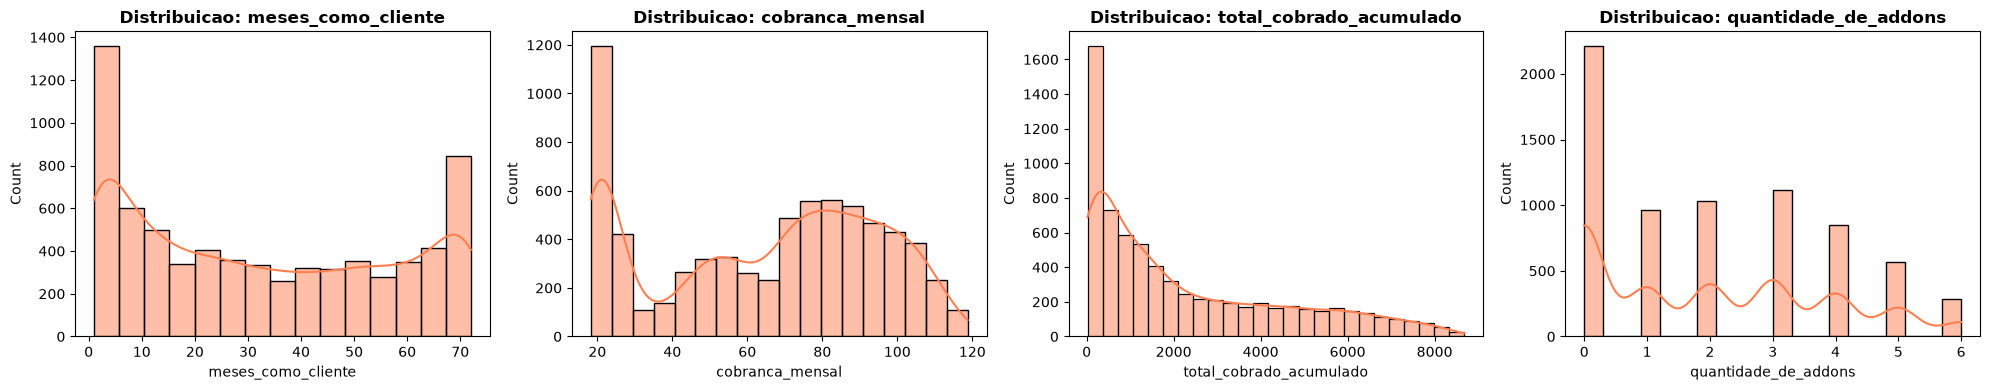

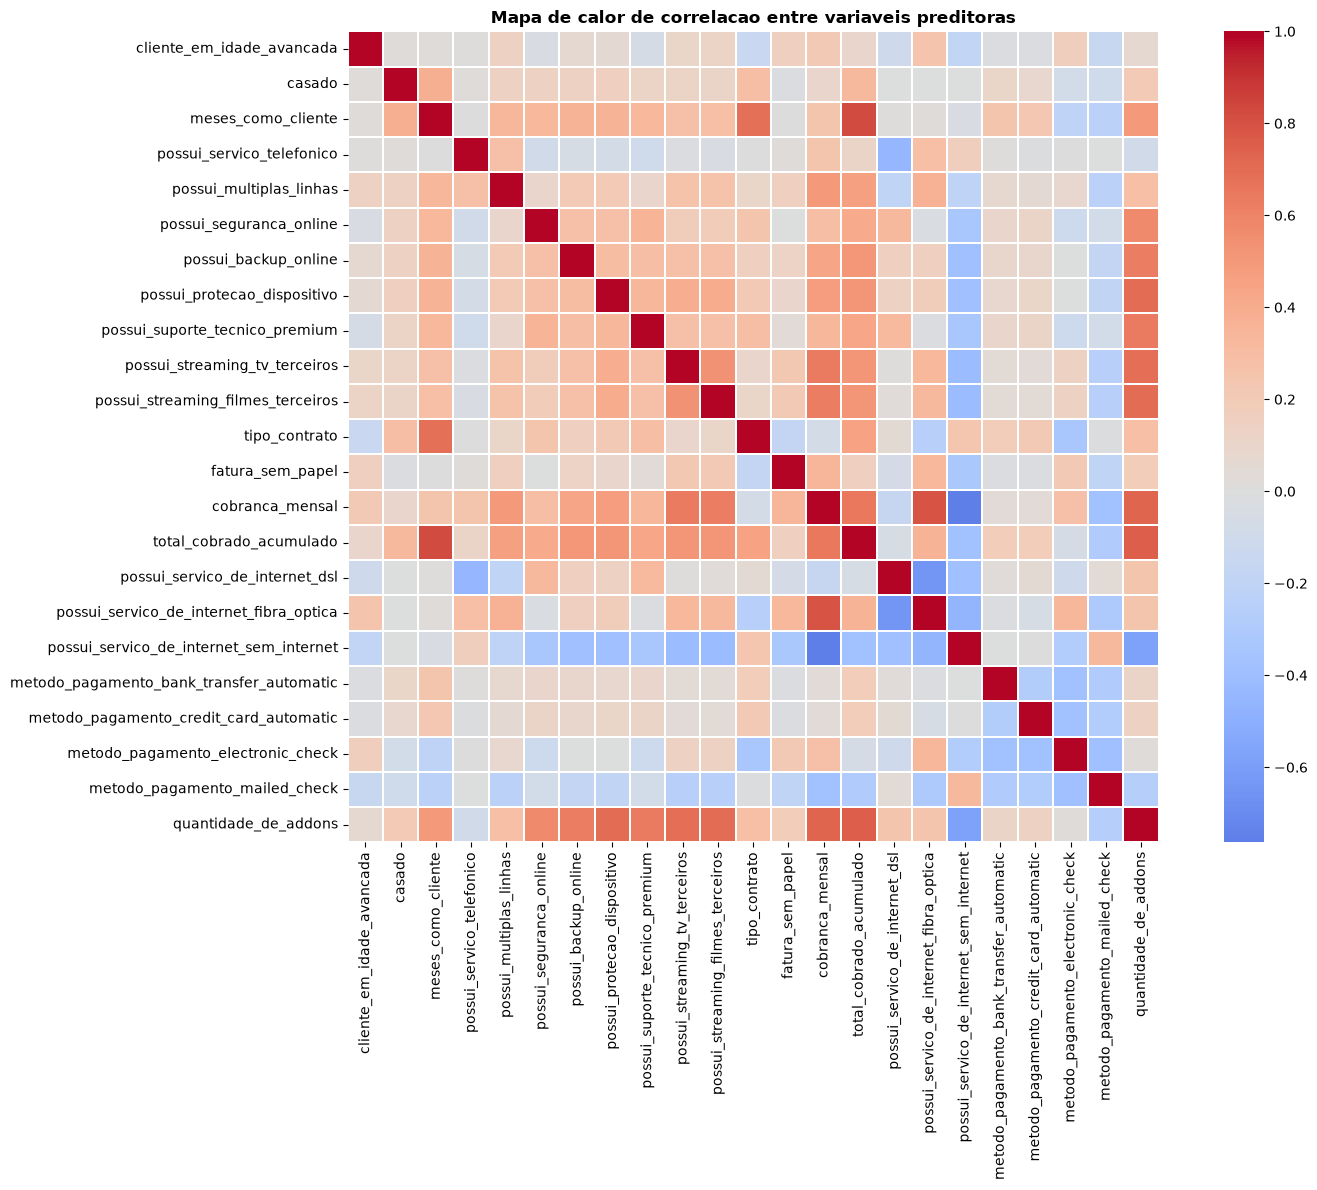

Pares de features preditoras com |correlacao| >= 0.5:
meses_como_cliente                       total_cobrado_acumulado                    0.826
cobranca_mensal                          possui_servico_de_internet_fibra_optica    0.787
                                         possui_servico_de_internet_sem_internet   -0.763
total_cobrado_acumulado                  quantidade_de_addons                       0.746
cobranca_mensal                          quantidade_de_addons                       0.725
possui_streaming_filmes_terceiros        quantidade_de_addons                       0.693
possui_protecao_dispositivo              quantidade_de_addons                       0.693
possui_streaming_tv_terceiros            quantidade_de_addons                       0.688
meses_como_cliente                       tipo_contrato                              0.677
cobranca_mensal                          total_cobrado_acumulado                    0.651
possui_servico_de_internet_dsl           possu

In [12]:
colunas_distribuicao = ["meses_como_cliente", "cobranca_mensal", "total_cobrado_acumulado", "quantidade_de_addons"]

exibir_distribuicao_e_correlacao(df_limpo, colunas_distribuicao, limiar_correlacao=0.5)

## Análise bivariada: features × target

O objetivo é responder: **quais características separam quem cancela de quem fica?** Isso orienta quais features criar, manter ou transformar.

A correlação com o target (seção anterior) só mede relações em linha reta e pode esconder padrões. Por isso usamos dois gráficos mais diretos:
- **Variáveis categóricas e discretas:** taxa de churn de cada categoria.
- **Variáveis numéricas contínuas:** distribuição separada entre quem cancelou e quem não cancelou.

### Taxa de churn por categoria

**Como ler:** cada barra é o % de clientes daquela categoria que cancelou. A linha tracejada é a taxa média da base (~27%).
- Barra **bem acima** da linha → grupo de risco.
- Barras **parecidas entre si** → a variável quase não diferencia os clientes.

Ao final, a variável com maior diferença entre a maior e a menor taxa é a que mais separa as classes.

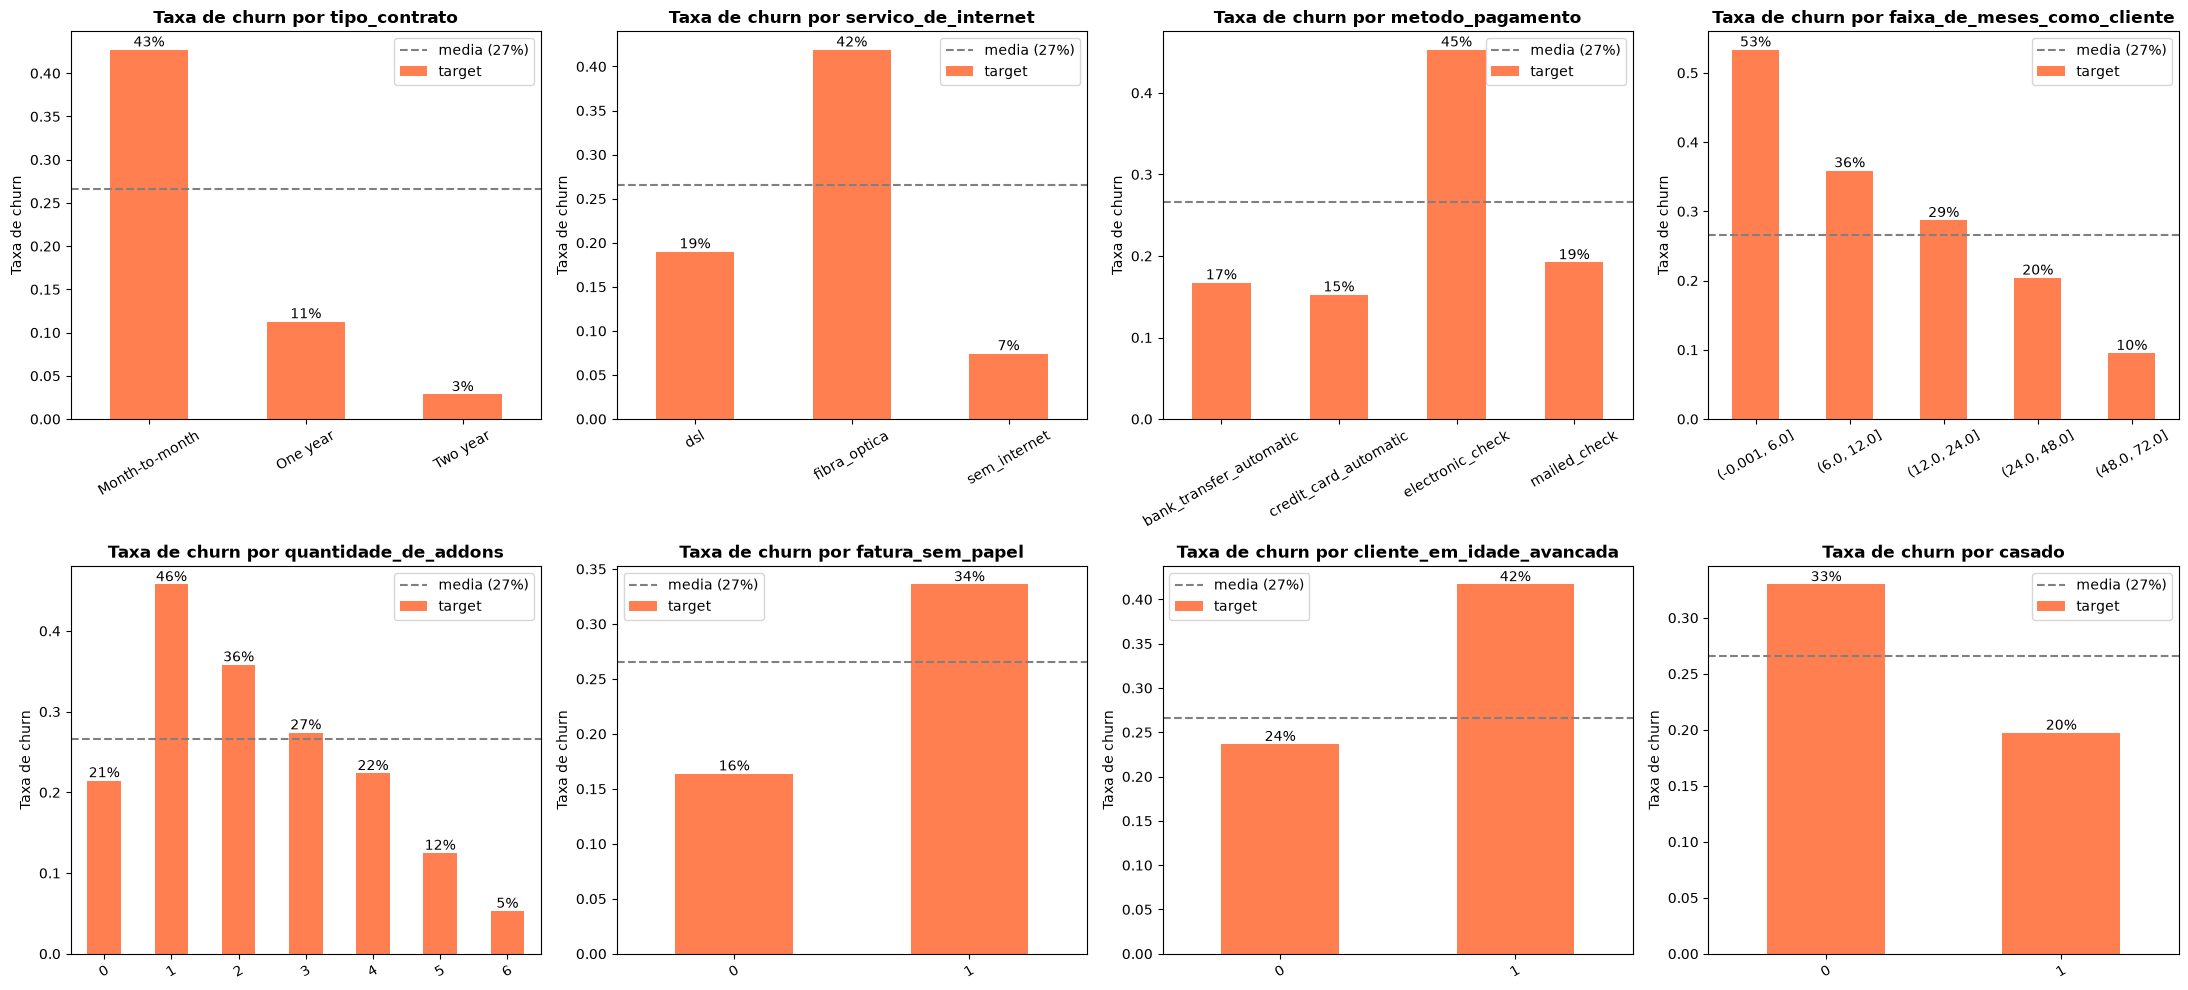

Diferenca entre a maior e a menor taxa de churn de cada variavel:
faixa_de_meses_como_cliente    44%
quantidade_de_addons           40%
tipo_contrato                  40%
servico_de_internet            34%
metodo_pagamento               30%
cliente_em_idade_avancada      18%
fatura_sem_papel               17%
casado                         13%


In [13]:
mapa_tipo_contrato = {"Month-to-month": 0, "One year": 1, "Two year": 2}
faixas_de_meses = [0, 6, 12, 24, 48, 72]

# Cada variável na forma mais legível para o gráfico (categorias originais em vez de códigos ou one-hot)
variaveis_categoricas = {
    "tipo_contrato": df_limpo["tipo_contrato"].map({codigo: nome for nome, codigo in mapa_tipo_contrato.items()}),
    "servico_de_internet": categoria_original(df_limpo, "possui_servico_de_internet"),
    "metodo_pagamento": categoria_original(df_limpo, "metodo_pagamento"),
    "faixa_de_meses_como_cliente": pd.cut(df_limpo["meses_como_cliente"], faixas_de_meses, include_lowest=True),
    "quantidade_de_addons": df_limpo["quantidade_de_addons"],
    "fatura_sem_papel": df_limpo["fatura_sem_papel"],
    "cliente_em_idade_avancada": df_limpo["cliente_em_idade_avancada"],
    "casado": df_limpo["casado"],
}

exibir_taxa_churn_por_categoria(df_limpo, variaveis_categoricas)

### Distribuição das variáveis numéricas por target

**Como ler:** se a caixa de quem cancelou estiver deslocada em relação à de quem não cancelou, a variável ajuda a separar as classes. A tabela abaixo dos gráficos mostra a mediana de cada grupo.

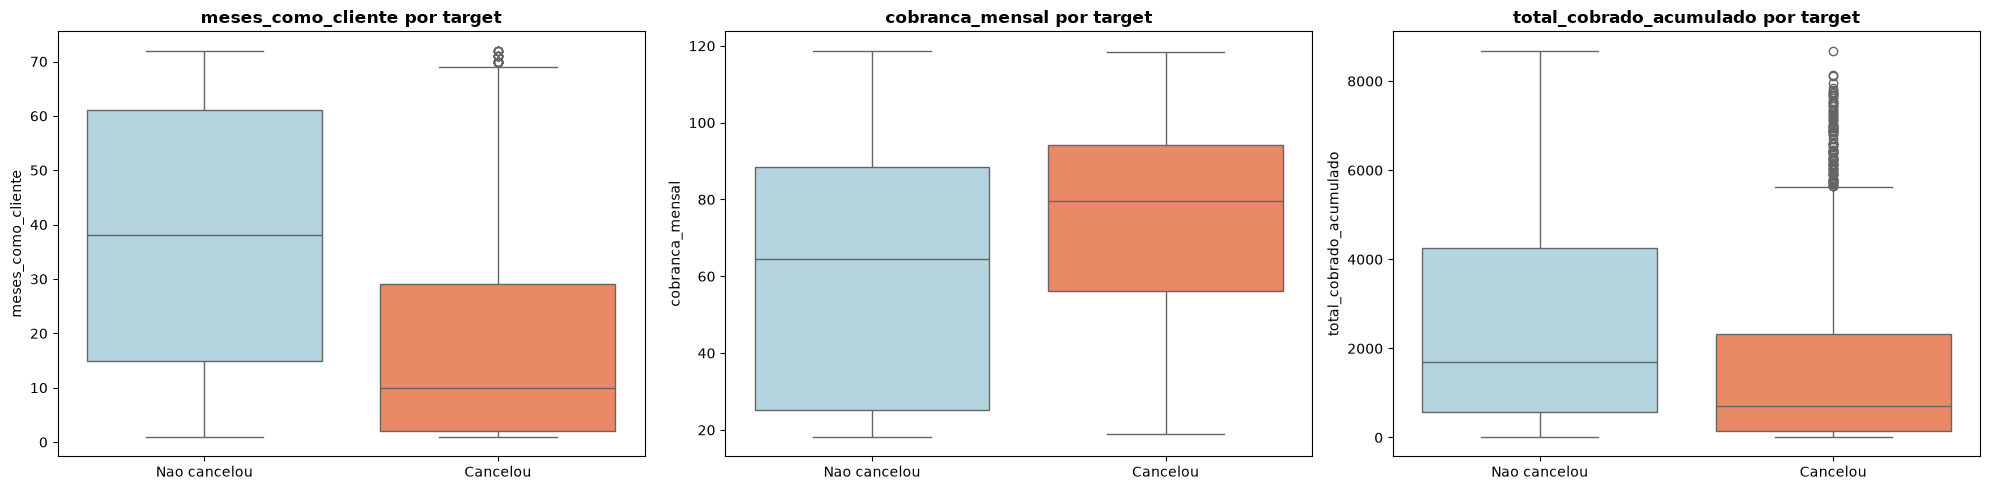

Mediana de cada variavel por target:


,meses_como_cliente,cobranca_mensal,total_cobrado_acumulado
target,,,
Nao cancelou,38.0,64.45,1683.60
Cancelou,10.0,79.65,703.55


In [14]:
colunas_numericas_bivariada = ["meses_como_cliente", "cobranca_mensal", "total_cobrado_acumulado"]

exibir_distribuicao_por_target(df_limpo, colunas_numericas_bivariada)

### Conclusões da análise bivariada

| Variável | O que mostra | Impacto no modelo |
|---|---|---|
| **Faixa de meses como cliente** | Maior diferença entre categorias: **53%** de churn até 6 meses contra **9,5%** acima de 48 meses. A queda é forte no início e depois desacelera | Justifica a feature **taxa de churn por faixa de meses**, que substitui a relação em linha reta |
| **Tipo de contrato** | Mensal **43%**, 1 ano **11%**, 2 anos **3%** | Principal fator de risco; mantido como ordinal |
| **Quantidade de addons** | Não é uma queda contínua: 0 addons **21%**, 1 addon **46%**, 6 addons **5%** | O grupo "0 addons" mistura clientes **sem internet** (7% de churn) com clientes com internet e sem nenhum addon (**52%**). Por isso a feature funciona junto com o tipo de internet |
| **Serviço de internet** | Fibra óptica **42%**, DSL **19%**, sem internet **7%** | Fibra é um grupo de risco, possivelmente pelo preço mais alto |
| **Método de pagamento** | Boleto eletrônico (`electronic_check`) **45%**; os demais entre 15% e 19% | Só o boleto eletrônico se destaca |
| **Fatura sem papel, idade avançada, casado** | Diferenças menores (13 a 18 pontos percentuais) | Contribuem, mas com menos peso |
| **Meses como cliente (numérico)** | Mediana de **10 meses** para quem cancelou contra **38** para quem ficou | Confirma que o churn se concentra nos primeiros meses |
| **Cobrança mensal** | Mediana de **R$ 79,65** para quem cancelou contra **R$ 64,45** para quem ficou | Quem paga mais cancela mais |
| **Total cobrado** | Mediana de **R$ 703** contra **R$ 1.684** | Reflete o tempo de casa (quem cancela ficou menos tempo), por isso é redundante com `meses_como_cliente` |

**Perfil de maior risco:** cliente novo, com contrato mensal, fibra óptica, pagamento por boleto eletrônico e sem serviços adicionais.

## Removendo feature redundante por alta colinearidade

`total_cobrado_acumulado` tem correlação de ~0,83 com `meses_como_cliente`: o total cobrado é, na prática, o tempo de casa multiplicado pela mensalidade. Manter as duas atrapalha a interpretação dos coeficientes, então o total cobrado sai.

In [15]:
coluna_redundante = "total_cobrado_acumulado"

df_sem_redundante = remover_colunas(df_limpo, [coluna_redundante])

df_sem_redundante.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,0,1,0,0,0,0,1,0,1
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,0,1,0,0,0,0,0,1,2
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,1,1,0,0,0,0,0,1,2
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,0,1,0,0,1,0,0,0,3
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,1,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,1,0,1,0,0,0,1,0,1
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,0,1,0,0,0,1,0,0,3
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,1,0,0,1,0,0,0,1,0
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,0,0,0,1,1,0,0,0,0


## Removendo linhas duplicadas

Clientes com todas as features idênticas poderiam cair ao mesmo tempo no treino e no teste, o que deixaria a avaliação otimista.

In [16]:
df_modelagem = remover_duplicatas(df_sem_redundante)

Linhas duplicadas encontradas: 73
Registros antes: 7032, Registros depois: 6959


## Proporção da variável target

O dataset é **desbalanceado**: cerca de 1 em cada 4 clientes cancela. Por isso:
- a acurácia sozinha engana (prever "ninguém cancela" já acerta ~74%);
- o treino usa **SMOTE** para equilibrar as classes.

Contagem:
target
0    5117
1    1842

Percentual:
Nao cancelou: 73.53%
Cancelou: 26.47%


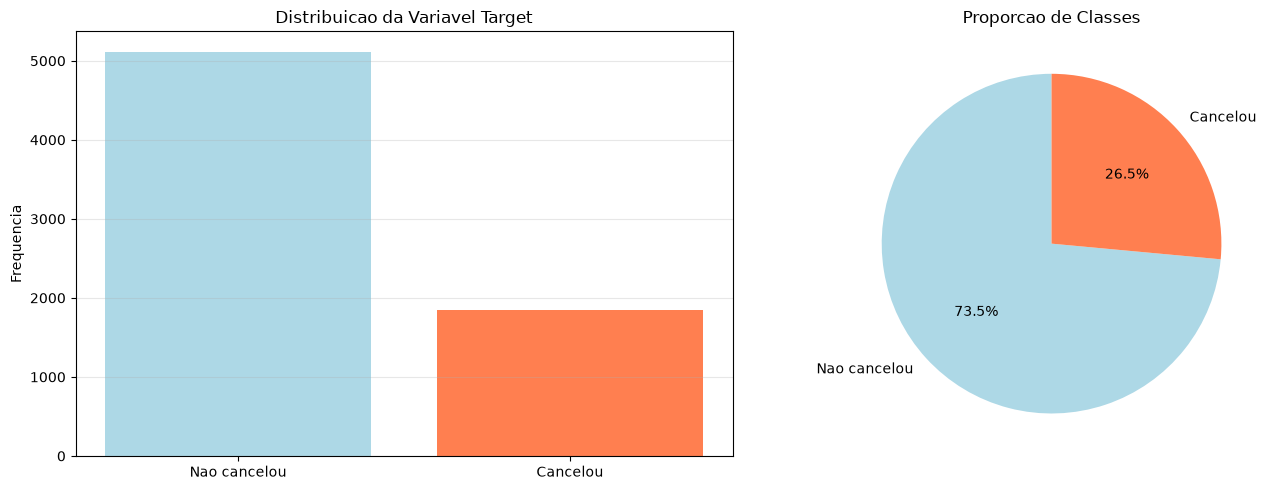


Ratio de balanceamento: 0.36


In [17]:
rotulos = ["Nao cancelou", "Cancelou"]

exibir_proporcao_target(df_modelagem, rotulos)

## Análise de dispersão das variáveis numéricas

Boxplots para verificar outliers. Um valor é contado como outlier quando está a mais de 3 desvios padrão da média (|z-score| > 3).

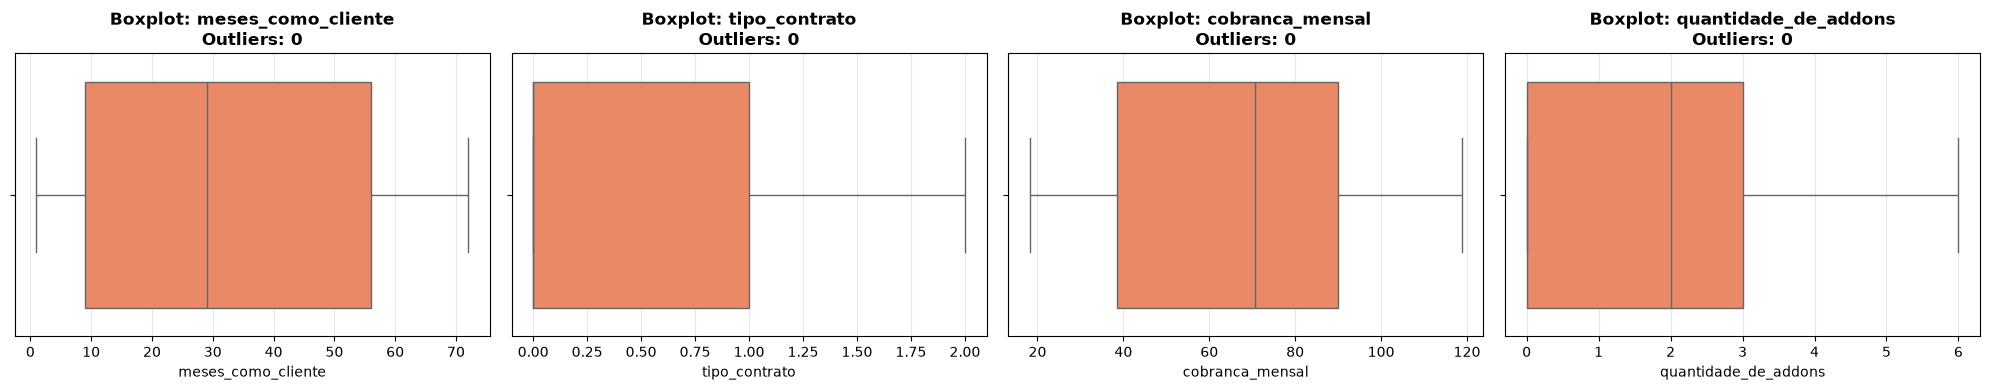

In [18]:
colunas_numericas_eda = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]

exibir_dispersao(df_modelagem, colunas_numericas_eda)

## Informações estatísticas

In [19]:
colunas_para_describe = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]

descrever_colunas(df_modelagem, colunas_para_describe)

,meses_como_cliente,tipo_contrato,cobranca_mensal,quantidade_de_addons
count,6959.00,6959.00,6959.00,6959.00
mean,32.62,0.69,65.11,2.06
std,24.46,0.83,29.97,1.84
min,1.00,0.00,18.25,0.00
25%,9.00,0.00,38.50,0.00
50%,29.00,0.00,70.55,2.00
75%,56.00,1.00,89.98,3.00
max,72.00,2.00,118.75,6.00


## Dividindo dados entre treino e teste

70% treino e 30% teste, com `stratify` para manter a mesma proporção de churn nos dois conjuntos.

In [20]:
X, y, X_train, X_test, y_train, y_test = dividir_treino_teste(
    df_modelagem,
    proporcao_teste=0.3,
    random_state=42,
)

X_train: (4871, 22), X_test: (2088, 22), y_train: (4871,), y_test: (2088,)


## Engenharia de features: taxa de churn por faixa de meses

`meses_como_cliente` é trocado pelo **% de clientes que cancelaram na faixa de meses** do cliente:

| Faixa | Clientes com |
|---|---|
| 1ª | 1 a 6 meses |
| 2ª | 7 a 12 meses |
| 3ª | 13 a 24 meses |
| 4ª | 25 a 48 meses |
| 5ª | 49 a 72 meses |

As faixas são mais estreitas no início, onde o risco muda rápido, e mais largas no fim, onde ele quase não muda.

> **Cuidado com vazamento de dados:** essa feature usa o `target`. A taxa de cada faixa é calculada **só com os dados de treino** e depois aplicada nos dados de avaliação. Se fosse calculada com a base inteira, o modelo "veria" as respostas do teste e as métricas ficariam otimistas.

In [21]:
faixas_de_meses = [0, 6, 12, 24, 48, 72]

# Taxa aprendida em cada faixa usando o conjunto de treino
resumir_churn_por_faixa(X_train, y_train, faixas_de_meses)

,clientes,taxa_de_churn
meses_como_cliente,,
"(-0.001, 6.0]",972,0.530
"(6.0, 12.0]",496,0.365
"(12.0, 24.0]",706,0.299
"(24.0, 48.0]",1149,0.198
"(48.0, 72.0]",1548,0.099


## Preparação para o treino: taxa por faixa, escalonamento e SMOTE

As três etapas ficam em uma única função, usada tanto no treino final quanto em cada fold da validação cruzada. Todas aprendem **apenas com o treino**:

1. **Taxa de churn por faixa de meses** (seção anterior).
2. **Escalonamento** (`StandardScaler`): deixa as colunas numéricas com média 0 e desvio 1, para que nenhuma domine o modelo só por ter valores maiores.
3. **SMOTE**: cria exemplos sintéticos da classe minoritária (churn) até as classes ficarem do mesmo tamanho. É aplicado **só no treino**; os dados de avaliação continuam com a proporção real.

In [22]:
faixas_de_meses = [0, 6, 12, 24, 48, 72]
colunas_para_escalonar = ["taxa_churn_faixa_meses", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]

X_train_balanceado, y_train_balanceado, X_test_preparado = preparar_para_treino(
    X_train, X_test, y_train,
    faixas_de_meses, colunas_para_escalonar, random_state=42,
)

print("Distribuicao antes do SMOTE:")
print(y_train.value_counts().to_string())
print("\nDistribuicao depois do SMOTE:")
print(y_train_balanceado.value_counts().to_string())

X_train_balanceado.head(n=100)

Distribuicao antes do SMOTE:
target
0    3582
1    1289

Distribuicao depois do SMOTE:
target
0    3582
1    3582


,cliente_em_idade_avancada,casado,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons,taxa_churn_faixa_meses
0,0,0,1,0,0,0,0,0,0,0,0.376981,0,-1.501215,0,0,1,0,1,0,0,-1.108116,0.635189
1,0,0,1,1,0,0,1,0,1,1,-0.827134,1,1.203069,0,1,0,0,0,1,0,0.508587,-0.419233
2,1,1,1,1,0,1,0,0,1,1,0.376981,1,1.066691,0,1,0,0,1,0,0,0.508587,-1.045924
3,0,1,1,1,0,0,0,1,0,0,-0.827134,1,0.454651,0,1,0,0,1,0,0,-0.569215,-0.419233
4,0,1,1,0,1,1,1,1,1,1,1.581097,0,0.640924,1,0,0,0,0,0,1,2.125290,-1.045924
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,1,0,1,1,0,1,1,0,1,1,1.581097,1,0.484588,1,0,0,1,0,0,0,1.047488,-1.045924
96,0,0,1,1,1,1,0,1,0,0,0.376981,1,-0.026000,1,0,0,0,0,0,1,0.508587,-0.419233
97,0,1,1,1,0,0,0,0,0,0,-0.827134,1,0.324925,0,1,0,0,0,1,0,-1.108116,0.635189
98,0,0,1,1,1,1,1,1,1,1,0.376981,1,1.768541,0,1,0,1,0,0,0,2.125290,-1.045924


## Modelo e métricas

Funções compartilhadas pela validação cruzada e pelo treino final.

| Métrica | O que responde |
|---|---|
| **Acurácia** | Quantos clientes o modelo classificou certo, no total |
| **Precisão** | Dos clientes apontados como churn, quantos realmente cancelaram |
| **Recall** | Dos clientes que cancelaram, quantos o modelo encontrou |
| **F1-score** | Equilíbrio entre precisão e recall |
| **ROC AUC** | O quanto o modelo dá nota maior para quem cancela do que para quem fica, independente do limiar |

## Validação cruzada estratificada (K-Fold)

Os dados são divididos em 5 partes (folds). Cada fold serve uma vez como validação, enquanto os outros 4 treinam o modelo. Isso mostra se o desempenho é estável ou se depende da divisão dos dados.

- **Estratificada:** cada fold mantém a proporção de churn da base.
- Em cada fold, `preparar_para_treino` recalcula a taxa por faixa, o escalonamento e o SMOTE **só com o treino daquele fold**.
- Com `random_state` fixo, os folds são os mesmos do V10. Dá para comparar as duas versões fold a fold.

**Como ler:** o `+/-` é o desvio padrão entre os folds. Diferenças entre versões menores que esse valor podem ser só variação natural.

In [23]:
faixas_de_meses = [0, 6, 12, 24, 48, 72]
colunas_para_escalonar = ["taxa_churn_faixa_meses", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]
parametros_modelo = {"l1_ratio": 1.0, "solver": "liblinear", "C": 1.0, "max_iter": 2000, "random_state": 42}

tabela_metricas_cv = validar_em_kfold(
    X, y,
    faixas_de_meses, colunas_para_escalonar, parametros_modelo,
    n_folds=5, random_state=42,
)

exibir_metricas_kfold(tabela_metricas_cv)

Metricas por fold:
 fold  acuracia  precisao  recall  f1_score  roc_auc
    1    0.8024    0.6013  0.7500    0.6675   0.8526
    2    0.7644    0.5422  0.6984    0.6105   0.8291
    3    0.7830    0.5724  0.7182    0.6370   0.8522
    4    0.7795    0.5695  0.6883    0.6233   0.8410
    5    0.7728    0.5563  0.6984    0.6193   0.8360

Media +/- desvio padrao entre os 5 folds:
acuracia: 0.7804 +/- 0.0142
precisao: 0.5683 +/- 0.0220
recall: 0.7106 +/- 0.0245
f1_score: 0.6315 +/- 0.0223
roc_auc: 0.8422 +/- 0.0102


## Treinamento final, seleção de features via Lasso (L1) e registro de métricas no DVC

O modelo é treinado com todo o conjunto de treino e avaliado uma única vez no teste.

- **Lasso (L1):** a penalidade pode zerar coeficientes de features pouco úteis, funcionando como seleção automática de features.
- **Registro:** as métricas são gravadas em `metrics/metrics.json` e exibidas pelo DVC. Para comparar com outra versão, use `dvc metrics diff`.

Features zeradas pelo Lasso (1): ['possui_servico_de_internet_sem_internet']

Coeficientes ordenados por magnitude:
quantidade_de_addons                        11.695965
possui_seguranca_online                     -7.274246
possui_suporte_tecnico_premium              -7.232841
possui_backup_online                        -6.777170
possui_protecao_dispositivo                 -6.733410
possui_streaming_filmes_terceiros           -6.641102
possui_streaming_tv_terceiros               -6.618531
metodo_pagamento_credit_card_automatic      -5.006872
metodo_pagamento_bank_transfer_automatic    -4.846801
metodo_pagamento_mailed_check               -4.766124
metodo_pagamento_electronic_check           -4.252774
cobranca_mensal                              2.175913
possui_servico_de_internet_fibra_optica     -1.927944
possui_servico_telefonico                   -1.790915
possui_servico_de_internet_dsl              -1.270496
tipo_contrato                               -0.721670
taxa_churn_faixa_mes

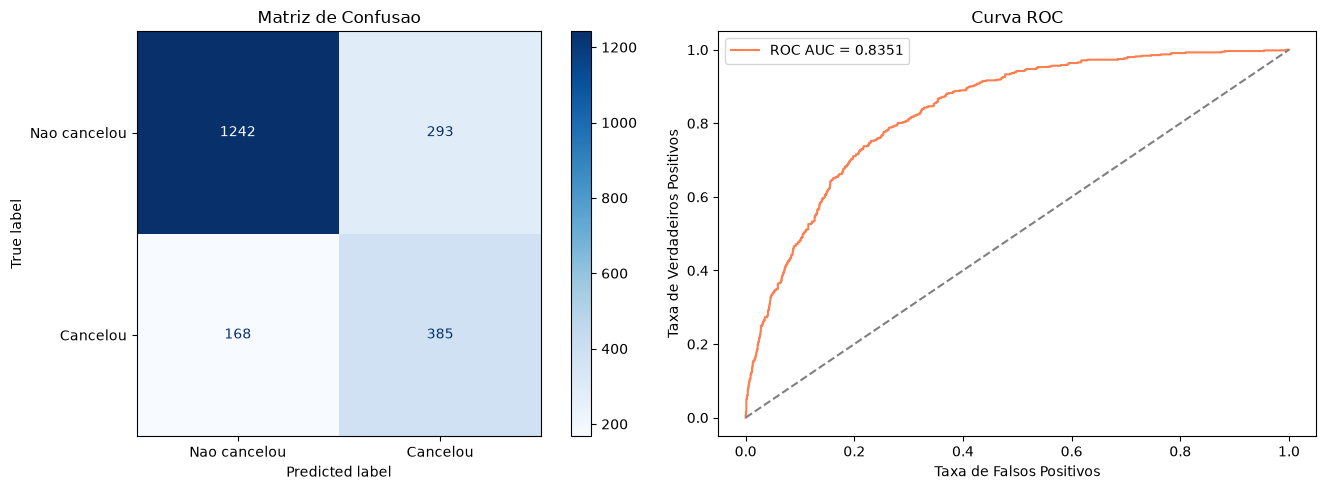

Path                                                                           acuracia    acuracia_cv_desvio    acuracia_cv_media    ccp_alpha_utilizado    class_weight_utilizado    cv_treino.acuracia.desvio    cv_treino.acuracia.media    cv_treino.f1_score.desvio    cv_treino.f1_score.media    cv_treino.precisao.desvio    cv_treino.precisao.media    cv_treino.recall.desvio    cv_treino.recall.media    cv_treino.roc_auc.desvio    cv_treino.roc_auc.media    f1_score    f1_score_cv_desvio    f1_score_cv_media    learning_rate_utilizado    max_depth_utilizado    melhores_parametros.mlp__alpha    melhores_parametros.mlp__learning_rate_init    min_samples_leaf_utilizado    min_samples_split_utilizado    n_estimators_utilizado    peso_classe_1_sample_weight    pesos_por_classe.0    pesos_por_classe.1    precisao    precisao_cv_desvio    precisao_cv_media    premissas_custo.custo_de_um_contato    premissas_custo.meses_de_receita_perdida    recall    recall_cv_desvio    recall_cv_media    roc

In [24]:
parametros_modelo = {"l1_ratio": 1.0, "solver": "liblinear", "C": 1.0, "max_iter": 2000, "random_state": 42}

modelo_regressao_logistica = treinar_modelo(X_train_balanceado, y_train_balanceado, parametros_modelo)

features_zeradas_pelo_lasso = exibir_coeficientes_lasso(modelo_regressao_logistica, X_train_balanceado.columns)

metricas = avaliar_modelo(modelo_regressao_logistica, X_test_preparado, y_test)
matriz_confusao, fpr, tpr = calcular_matriz_e_roc(modelo_regressao_logistica, X_test_preparado, y_test)

exibir_metricas_classificacao(metricas, matriz_confusao)

# Gráficos: matriz de confusão e curva ROC
exibir_matriz_e_roc(matriz_confusao, fpr, tpr, metricas["roc_auc"])

# Grava as métricas para o DVC
pasta_metricas = Path("metrics")
salvar_metricas(
    {
        **metricas,
        "features_zeradas_pelo_lasso": features_zeradas_pelo_lasso,
        "matriz_confusao": matriz_confusao.tolist(),
    },
    pasta_metricas,
)

# Exibe as métricas registradas
resultado_dvc = consultar_metricas_dvc("../../..")